# 08A.2 — Outcome semantics and opportunity validation

**Status: AUTHORED 2026-10-13 — AWAITING USER EXECUTION.** Nothing here has been run by its author; no number below exists yet.

**Motivation.** Notebook 08A showed that `FO01.separation_at_pass_forward`, `FO12.tackle` and `FO13.sack` are *observable*. Observable is not the same as *meaningful*: before a single Combine feature is related to them, each must have a known definition, a known unit, a legitimate opportunity denominator, enough linked athletes and a value that is reproducible across independent games.

**Question.** Can any of the three be read as an outcome of an NFL player, under which opportunity rule, and is it ready to be frozen as a target of the football-outcome transfer study (08B)?

**Hypotheses stated before running (each can fail).**
- H-S1 — separation is a non-negative distance in yards, recorded for targeted *and* non-targeted route runners.
- H-S2 — the athlete mean of separation is reproducible across game halves, and the ranking of athletes does not depend strongly on the opportunity rule (S0 / S1 / S2).
- H-T — a recorded `tackle` row exists only when a tackle statistic was credited, so `mean(tackle | recorded)` is **not** a tackle rate.
- H-K — `sack` is recorded (with explicit zeros) on defensive pass-play rows, which are not the same thing as pass-rush opportunities.

| Section | Brief | Outputs |
|---|---|---|
| 1 | source audit, semantic status | `football_outcome_candidates_v1`, `football_outcome_semantics_audit`, fig 01 |
| 2 | missing versus zero, credit per play | `football_outcome_zero_missing`, `football_outcome_play_credit`, fig 02 |
| 3 | FO01 separation validation | `football_separation_distribution`, `football_outcome_structure`, figs 03–05 |
| 4 | context relevance, route × alignment | `football_outcome_context_fields`, `football_separation_context_cells`, fig 06 |
| 5 | tackle and sack audits | figs 07–08 |
| 6 | opportunity denominators | `football_opportunity_denominators`, `football_opportunity_seasons` |
| 7 | game-split reliability | `football_outcome_reliability`, `…_reliability_exposure`, `…_exposure_dependence`, figs 09–10 |
| 8 | ranking sensitivity | `football_outcome_ranking_sensitivity`, fig 13 |
| 9 | linked Combine cohort | `football_outcome_linked_cohort`, `football_outcome_cohort_support`, figs 11–12 |
| 10 | readiness screen, rule-based proposal | `football_outcome_screen` |
| 11 | **explicit manual freeze**, gate 08A.2 | `football_outcome_freeze_proposal.json`, `football_outcome_targets_<version>.json`, fig 14 |

**Scientific data contract.**
- Unit of analysis: the athlete. Population: eligible player-plays of notebook 05A (REG season, in-scope position, not nullified by penalty, usable quality tier), declared positions of each outcome.
- A null is never read as 0. Only the denominators that *declare* that reading (`structural`) keep null rows, and that caps their status at `provisional`.
- Every reliability split is by **whole games** — never by player-play.
- No Combine measurement is read. The linked cohort uses the linkage *flags* of the Milestone 06 manifest and counts only; no outcome is related to a Combine feature here, and no definition is tuned on one.
- The Milestone 05 registry `nfl_movement_targets_v1` and every Milestone 06 result are read-only. This notebook writes under `…/advanced_movement/scouting_v1/` only.

**Assumptions (not facts).** The repository holds no vendor data dictionary: definitions start as `plausible_inferred`. The delivered tracking and `player_play` rows cover the project athletes, not all 22 players, so nearest-defender distance cannot be recomputed. `pass_result` codes and the `NO_ASSIGNMENT` token are read as the vendor wrote them; their meaning is inferred.

**Prerequisites (same `RUN_MODE`).** 05A, 05B (frozen), 06A (cohort manifest), 08A. No PyTorch.

In [1]:
# ---------------------------------------------------------------- Configuration
RUN_MODE = 'full'             # 'smoke' | 'full' — must match notebooks 05A / 05B / 06A / 08A
SEED = 20261011
FORCE_REBUILD = False          # True = recompute a stage even when its cached tables are current
SAVE_TABLES = True
SAVE_FIGURES = True
EXPERIMENT_VERSION = '08A2.1'  # part of every cache key and provenance record
BOOTSTRAP_ITERATIONS = 1000    # athlete bootstrap of the odd / even reliability (smoke mode uses 100)
RANDOM_GAME_SPLITS = 100       # random game-half splits (smoke mode uses 10)
NUM_WORKERS = 0                # kept for interface parity: this notebook is single-process

## 0. Setup, inputs, synthetic validation

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import time
from dataclasses import replace

import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.tables import LayerRefs
from nflbdb.data.utils import utc_now
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import nfl_outcomes as no
from nflbdb.research.advanced_movement import opportunity_validation as ov
from nflbdb.research.advanced_movement import outcome_semantics as osm
from nflbdb.research.advanced_movement import outcome_validation_figures as ovf
from nflbdb.research.advanced_movement import scouting_feasibility as sf
from nflbdb.research.advanced_movement import scouting_validation as sv
from nflbdb.research.advanced_movement import transfer as tr
from nflbdb.research.advanced_movement.artifacts import ScoutingStore

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
vc = ov.ValidationConfig().for_mode(controls)
if not controls.smoke:
    vc = replace(vc, n_boot=BOOTSTRAP_ITERATIONS, n_random_splits=RANDOM_GAME_SPLITS)
store = ScoutingStore(cfg, controls)
refs = LayerRefs(cfg)
amc.seed_everything(controls.seed)
NB = {'05A': '05a_nfl_movement_outcome_eda.ipynb', '06A': '06a_transfer_cohort_and_leakage_audit.ipynb',
      '08A': '08a_football_outcome_feasibility.ipynb', '08A2': '08a2_outcome_semantics_and_opportunity_validation.ipynb'}

# ---- the frozen Milestone 05 registry gives the configuration of the 05A play table: read, verified, never written
registry_doc, freeze_audit = tr.audit_freeze(store.nfl, controls.run_mode)
tr.assert_frozen(freeze_audit)
_, ocfg = tr.frozen_targets(registry_doc)
plays = store.nfl.require(no.plays_contract(ocfg), NB['05A'])
PLAYS_FILE = store.nfl.parquet(no.plays_contract(ocfg))

# ---- 08A feasibility registry: the three audited outcomes must be the ones it called observable (read only)
registry_08a = store.require(sf.REGISTRY, NB['08A'])
AUDITED = [s.outcome_id for s in osm.SEMANTICS]
status_08a = dict(registry_08a.filter(pl.col('outcome_id').is_in(AUDITED)).select('outcome_id', 'status').iter_rows())
assert set(status_08a) == set(AUDITED), f'08A registry does not hold the audited outcomes: {status_08a}'

# ---- Combine cohort manifest of Milestone 06: linkage FLAGS only (no Combine measurement is a column of it)
manifest = store.transfer.require_named('transfer_cohort_manifest', NB['06A'])
MANIFEST_FILE = store.transfer.data_dir / 'transfer_cohort_manifest.parquet'

# ---- the audited vendor fields joined to the tracked player-plays (every 05A row kept; absent fields stay absent)
t0 = time.perf_counter()
PP_FILES = list(refs.files('silver', 'player_play'))
SCHEMAS = sf.source_schemas(refs)
base, DUP = osm.semantic_base(plays, refs.scan('silver', 'player_play'))
ABSENT_FIELDS = [f for f in osm.AUDIT_FIELDS if f not in base.columns]

label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · {plays.height:,} tracked player-plays · {int(plays["eligible"].sum()):,} eligible · '
                 f'{plays["nfl_id"].n_unique()} athletes · {plays["game_id"].n_unique()} games · semantics `{osm.definition_hash()}` · '
                 f'denominators `{ov.denominators_hash()}` · Combine manifest: {manifest.height} athletes'))
print(f'semantic base built in {time.perf_counter() - t0:.0f} s · vendor rows: {DUP} · 08A statuses: {status_08a}')
print(f'audited fields absent from silver.player_play (not created): {ABSENT_FIELDS or "none"}')
display(store.describe())

**Run mode: `full`** (FULL) · 251,089 tracked player-plays · 242,043 eligible · 401 athletes · 815 games · semantics `84750edb2d16171b` · denominators `a03e896f0f00d63d` · Combine manifest: 510 athletes

semantic base built in 0 s · vendor rows: {'n_vendor_rows': 314197, 'n_player_plays': 314197, 'n_duplicate_rows': 0, 'n_conflicting_rows': 0} · 08A statuses: {'FO01.separation_at_pass_forward': 'observable', 'FO12.tackle': 'observable', 'FO13.sack': 'observable'}
audited fields absent from silver.player_play (not created): ['receiver_alignment', 'offense_formation', 'pass_length', 'team_coverage_man_zone', 'team_coverage_type', 'yards_gained']


what,where
str,str
"""run mode""","""full"""
"""tables (CSV)""","""reports/tables/advanced_moveme…"
"""datasets (Parquet + schema sid…","""warehouse/gold/advanced_moveme…"
"""figures (PNG 300 DPI, SVG, PDF…","""reports/figures/advanced_movem…"
"""models and fitted preprocessin…","""artifacts/models/advanced_move…"


In [3]:
# ---- synthetic validation (planted, known answers; no project data). A failure stops the notebook.
validation = sv.run_all(sv.CHECKS_08A2)
with pl.Config(fmt_str_lengths=500, tbl_rows=-1):
    display(validation)
sv.assert_all_passed(validation)

C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\advanced_movement\opportunity_validation.py:382: RuntimeWarning: Mean of empty slice
  row |= {"r_half": float(reps_a.mean()), "rel_sb": _fn(np.nanmean(sb)), "rel_lo": _fn(np.nanpercentile(sb, 2.5)),
c:\Users\myben\.conda\envs\nfl\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1409: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
18:39:52 | INFO    | nflbdb.research.advanced_movement.opportunity_validation | [football_outcomes] football_outcome_targets_v1.json written: ['FO01.S0']
18:39:52 | INFO    | nflbdb.research.advanced_movement.opportunity_validation | [football_outcomes] football_outcome_targets_v2.json written: ['FO01.S1']


check,status,detail
str,str,str
"""outcome_semantics_status""","""PASS""","""inferred by default; confirmed only with a named source and quoted definition; blocking failures give unresolved"""
"""zero_versus_missing""","""PASS""","""null, recorded zero and positive are counted apart; a null enters a rate only in the denominators that declare that reading"""
"""opportunity_denominators""","""PASS""","""11 denominators match the planted row counts and rates; absent fields give no denominator; positions are respected"""
"""duplication_and_join""","""PASS""","""duplicated vendor rows never multiply player-plays; conflicting duplicates are counted and block"""
"""athlete_aggregation""","""PASS""","""athlete value = sum / count over whole games; interval from resampled games; support and percentiles by rule"""
"""game_split_reliability""","""PASS""","""planted game-split reliability recovered (odd / even 0.744, random 0.723, closed form 0.706); no-trait r -0.033"""
"""cohort_linking""","""PASS""","""linked-cohort funnel, model-family eligibility and position × cohort support match the planted flags"""
"""screen_and_proposal""","""PASS""","""screen statuses follow semantics, denominator legitimacy, linked support and reliability; the proposal follows the pre-declared order"""
"""explicit_freeze""","""PASS""","""nothing is frozen without an explicit, reasoned decision; the registry is immutable and versioned; 08B is gated on it"""


## 1. Outcome source audit and semantic status

For every candidate: field, source, type, unit, the **declared** definition (an assumption written before reading a value), event definition, zero encoding, missing-value meaning, attribution, opportunity statement, eligibility, seasons, measured presence.

Three statuses, never merged:
- `confirmed_source` — you recorded the vendor definition below (`DEFINITION_EVIDENCE`): a named source **and** the quoted definition. A column name confirms nothing.
- `plausible_inferred` — the default: column name + internal consistency.
- `unresolved` — a blocking consistency check failed (negative distance, undeclared credit value, conflicting duplicates, absent field), or you declared it so.

**Fill `DEFINITION_EVIDENCE` only from the competition data dictionary.** Leave it empty if you do not have it — the outcome then stays `plausible_inferred` and can be frozen only with an explicit written acknowledgement (section 11).

18:39:52 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:08a2_semantics] computing (never run)
18:39:53 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08a2_semantics] football_outcome_candidates_v1: 3 rows → warehouse/gold/advanced_movement/scouting_v1/football_outcome_candidates_v1.parquet
18:39:53 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08a2_semantics] football_outcome_semantics_audit: 29 rows → warehouse/gold/advanced_movement/scouting_v1/football_outcome_semantics_audit.parquet
18:39:53 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08a2_semantics] football_outcome_zero_missing: 96 rows → warehouse/gold/advanced_movement/scouting_v1/football_outcome_zero_missing.parquet
18:39:53 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08a2_semantics] football_outcome_structure: 91 rows → warehouse/gold/advanced_movement/scouting_v1/football_outcome_structure.parquet
18:

outcome_id,value_field,source_table,dtype,unit,positions,seasons,n_rows,n_observed,n_zero,n_positive,observed_share,definition_status,status_basis
str,str,str,str,str,str,str,i64,i64,i64,i64,f64,str,str
"""FO01.separation_at_pass_forward""","""separation_at_pass_forward""","""silver.player_play""","""Float64""","""yd""","""WR · TE""","""2023 · 2024 · 2025""",44960,37398,0,37398,0.831806,"""plausible_inferred""","""inferred from the column name and internal consistency; no vendor definition recorded"""
"""FO12.tackle""","""tackle""","""silver.player_play""","""Int64""","""count per player-play""","""DB · DL""","""2023 · 2024 · 2025""",114277,9243,3630,5613,0.080882,"""plausible_inferred""","""inferred from the column name and internal consistency; no vendor definition recorded"""
"""FO13.sack""","""sack""","""silver.player_play""","""Float64""","""sacks per player-play (0, 0.5, 1)""","""DL""","""2023 · 2024 · 2025""",50363,28962,28567,395,0.575065,"""plausible_inferred""","""inferred from the column name and internal consistency; no vendor definition recorded"""


outcome_id,declared_definition,event_definition,zero_encoding,missing_meaning,attribution,opportunity,limits
str,str,str,str,str,str,str,str
"""FO01.separation_at_pass_forward""","""distance from the player to the nearest defender at the frame tagged pass_forward""","""one value per player-play, sampled at the pass release; the release frame itself is not delivered with the value""","""0 would be a physical distance of zero; no structural zero is expected""","""null = not recorded (no pass released, or the player was not in a route) — never read as a separation of 0""","""recorded on the receiver's row; the defender is not named""","""route snaps on plays with a released pass; whether non-targeted receivers are included is MEASURED, not assumed""","""an interaction outcome: receiver, nearest defender, coverage call, route depth and throw timing together"""
"""FO12.tackle""","""the player was credited with a (solo) tackle on the play""","""a credited statistic of the play, not a tracking event; the tracking tag 'tackle' marks a frame of the play""","""a recorded 0 exists: its meaning (assist only, missed tackle, other credited action) is MEASURED against the companion fields""","""null = no tackle statistic recorded for the player on the play; 'no credit' is an inference, not a recorded 0""","""player-level credit; solo versus assisted depends on the companion field 'assist'""","""no field records a tackle OPPORTUNITY (plays run at the player, tackle attempts); only snaps on the field are observed""","""credit depends on role, scheme, run direction and playing time; a raw count is not a tackling skill"""
"""FO13.sack""","""sack credit of the player on the play (0.5 = shared sack)""","""a credited statistic of the play; the tracking tag 'qb_sack' marks a frame of the play""","""0 is recorded explicitly on a subset of plays; which plays is MEASURED (it is not assumed to be pass-rush snaps)""","""null = no sack statistic recorded on the play (for instance a run play) — never read as 0""","""player-level credit share""","""the recorded rows are a candidate denominator; whether the player actually rushed the passer on them is not recorded""","""rare event; depends on rush assignment, protection, quarterback and game script"""


outcome_id,check,observed,passed,blocking,meaning
str,str,str,bool,bool,str
"""FO01.separation_at_pass_forward""","""field_present""","""separation_at_pass_forward: present""",true,true,"""the value field exists in silver.player_play"""
"""FO01.separation_at_pass_forward""","""one_row_per_player_play""","""0 conflicting duplicates (0 duplicated rows)""",true,true,"""duplicated vendor rows carry the same values (the first is kept)"""
"""FO01.separation_at_pass_forward""","""recorded_share""","""37,398 of 44,960 eligible player-plays (83.2 %)""",null,false,"""share of eligible player-plays of the declared positions with a recorded value"""
"""FO01.separation_at_pass_forward""","""recorded_zero""","""0 recorded zeros · 37,398 positive""",null,false,"""a recorded zero is a statement by the vendor; a null is not"""
"""FO01.separation_at_pass_forward""","""non_negative""","""min 0.128""",true,true,"""a distance cannot be negative"""
"""FO01.separation_at_pass_forward""","""unit_plausible_yards""","""median 2.67""",true,true,"""a median nearest-defender distance outside 0.5–10 yd contradicts 'yards' (range declared before reading)"""
"""FO01.separation_at_pass_forward""","""recorded_for_non_targeted""","""targeted 100.0 % · not targeted 84.8 %""",true,false,"""if the value existed for targeted receivers only, the quarterback's choice would select the plays"""
"""FO01.separation_at_pass_forward""","""route_label_coverage""","""100.0 % of recorded values carry a route label · 87.5 % of labelled routes carry a value""",null,false,"""the route label documents that the player was in a route (denominator S1)"""
"""FO01.separation_at_pass_forward""","""nearest_defender_recomputable""","""median 2 tracked athletes per play (max 11)""",false,false,"""with only the project athletes tracked, 'distance to the nearest defender' cannot be recomputed from tracking"""


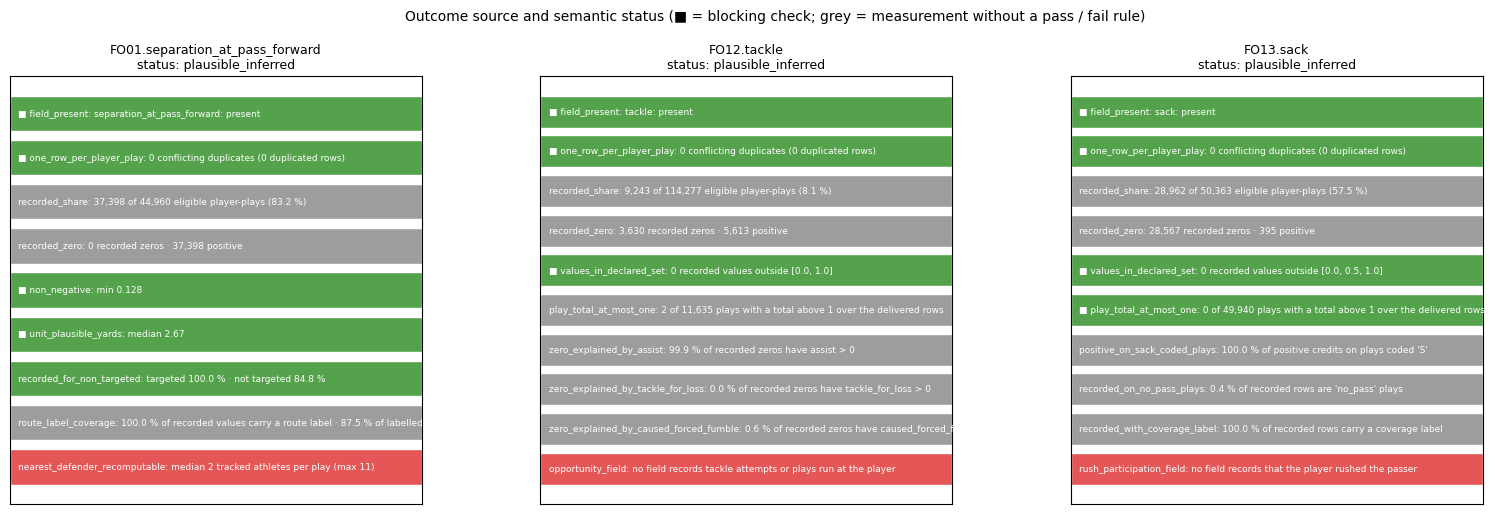

In [4]:
# ---- analyst evidence. Example (do NOT keep the example text — quote the real dictionary):
# DEFINITION_EVIDENCE = {'FO01.separation_at_pass_forward': {'status': 'confirmed_source', 'source': '<document, section>',
#                                                            'definition': '<quoted vendor definition, with its unit>'}}
DEFINITION_EVIDENCE = {}

PARAMS = {'experiment_version': EXPERIMENT_VERSION, 'validation': vc.params(), 'semantics': osm.definition_hash(),
          'denominators': ov.denominators_hash(), 'definition_evidence': DEFINITION_EVIDENCE}
SOURCE_FILES = [cfg.paths.rel(p) for p in PP_FILES]

sem = store.build('08a2_semantics', osm.CONTRACTS,
                  lambda: osm.run_semantics(base, DUP, refs.scan('silver', 'player_play'), plays, SCHEMAS, SOURCE_FILES, DEFINITION_EVIDENCE,
                                            vc.extreme_yd, vc.min_cell_obs, vc.min_cell_athletes),
                  params=PARAMS, files=[PLAYS_FILE, *PP_FILES])
candidates, checks = sem[osm.CANDIDATES.name], sem[osm.CHECKS.name]
SEMANTIC = osm.status_from_table(candidates)
with pl.Config(fmt_str_lengths=400, tbl_rows=-1, tbl_width_chars=320):
    display(candidates.select('outcome_id', 'value_field', 'source_table', 'dtype', 'unit', 'positions', 'seasons', 'n_rows', 'n_observed',
                              'n_zero', 'n_positive', 'observed_share', 'definition_status', 'status_basis'))
    display(candidates.select('outcome_id', 'declared_definition', 'event_definition', 'zero_encoding', 'missing_meaning', 'attribution',
                              'opportunity', 'limits'))
    display(checks)
store.show(ovf.fig_semantic_status(checks, candidates), 'AM08A2_01_outcome_semantic_status', {'checks': checks},
           source='football_outcome_semantics_audit', n=f'{candidates.height} outcomes',
           note='green = pass, red = fail, grey = measurement without a pass / fail rule; square = blocking check')

## 2. Missing versus zero; credit per play

`n_null` (not recorded), `n_zero` (the vendor recorded a 0) and `n_positive` are counted apart, by position. The second table sums a credit over the **delivered** player rows of a play: a shared credit (sack: 0.5 + 0.5) cannot exceed 1. The delivered rows are not all 22 players, so a total below 1 proves nothing; a total above 1 contradicts the declared attribution.

field,position_group,dtype,n_rows,n_null,n_zero,n_positive,n_negative,share_null,share_zero
str,str,str,i64,i64,i64,i64,i64,f64,f64
"""assist""","""ALL""","""Int64""",242043,232634,5763,3646,0,0.9611,0.0238
"""assist""","""DB""","""Int64""",63914,58115,3854,1945,0,0.9093,0.0603
"""assist""","""DL""","""Int64""",50363,46919,1762,1682,0,0.9316,0.0350
"""assist""","""OL""","""Int64""",82806,82768,28,10,0,0.9995,0.0003
"""assist""","""TE""","""Int64""",8124,8106,15,3,0,0.9978,0.0018
"""assist""","""WR""","""Int64""",36836,36726,104,6,0,0.9970,0.0028
"""coverage_assignment""","""ALL""","""String""",242043,173469,0,68574,0,0.7167,0.0000
"""coverage_assignment""","""DB""","""String""",63914,24384,0,39530,0,0.3815,0.0000
"""coverage_assignment""","""DL""","""String""",50363,21319,0,29044,0,0.4233,0.0000


field,total_credit,n_plays,median_rows_recorded
str,f64,i64,f64
"""assist""",0.0000,7329,1.0000
"""assist""",1.0000,4095,1.0000
"""assist""",2.0000,211,2.0000
"""sack""",0.0000,49393,1.0000
"""sack""",0.5000,104,2.0000
"""sack""",1.0000,443,2.0000
"""tackle""",0.0000,4260,1.0000
"""tackle""",1.0000,7373,1.0000
"""tackle""",2.0000,2,1.5000


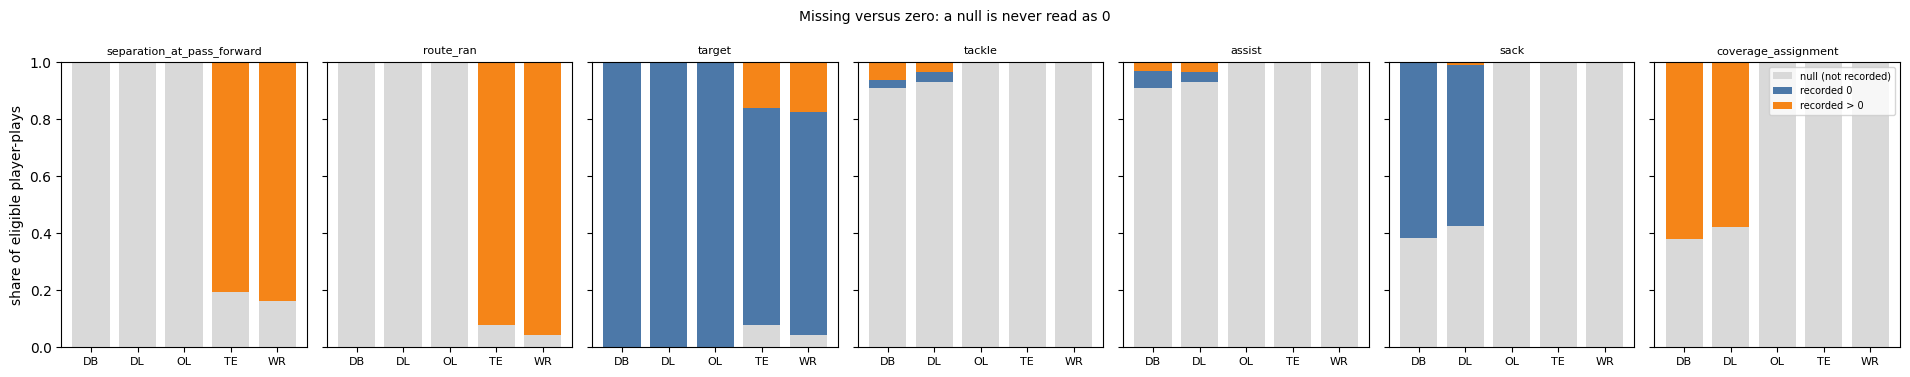

In [5]:
zero_missing, credit = sem[osm.ZERO_MISSING.name], sem[osm.CREDIT.name]
with pl.Config(tbl_rows=-1, tbl_width_chars=220, float_precision=4):
    display(zero_missing.filter(pl.col('field').is_in(['separation_at_pass_forward', 'route_ran', 'target', 'tackle', 'assist', 'sack',
                                                        'coverage_assignment'])))
    display(credit)
store.show(ovf.fig_missing_zero(zero_missing), 'AM08A2_02_missing_versus_zero', {'zero_missing': zero_missing},
           source='football_outcome_zero_missing', n=f'{int(plays["eligible"].sum()):,} eligible player-plays',
           note='shares of eligible player-plays by position group; a null is not a zero')

## 3. FO01 — separation validation

What is verified here: non-negative values in a plausible yard range; whether **non-targeted** receivers carry a value; how often a recorded value has a route label; distribution by position and by target status; extreme values (counted above the dashed line, **not removed**); availability by season, alignment, route and coverage family.

What cannot be verified: that the value is the distance to the *nearest defender* at the `pass_forward` frame. The delivered tracking holds only the project athletes (see check `nearest_defender_recomputable`), so that reading is confirmed only by the vendor definition you record in section 1.

Reading rule: separation is an **interaction outcome** — receiver, defender, coverage call, route and throw timing together. A difference between targeted and non-targeted plays is expected (the quarterback throws to the open receiver): that is why target status is never a filter of a primary definition.

position_group,target,n_obs,n_athletes,mean,sd,p05,p25,median,p75,p95,max,share_extreme,share_below_half_yard
str,str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""ALL""","""ALL""",37398,116,3.153,2.160,0.738,1.417,2.670,4.360,7.207,22.794,0.001,0.006
"""ALL""","""not_targeted""",29665,116,2.993,2.064,0.717,1.342,2.521,4.121,6.844,22.794,0.001,0.007
"""ALL""","""targeted""",7733,107,3.769,2.399,0.881,1.772,3.365,5.256,8.154,17.716,0.001,0.003
"""TE""","""ALL""",6546,33,3.357,2.355,0.717,1.487,2.854,4.564,7.860,22.794,0.001,0.008
"""TE""","""not_targeted""",5234,33,3.129,2.272,0.679,1.348,2.590,4.264,7.528,22.794,0.001,0.009
"""TE""","""targeted""",1312,28,4.268,2.461,0.945,2.332,4.026,5.683,8.940,15.056,0.001,0.002
"""WR""","""ALL""",30852,83,3.110,2.114,0.741,1.405,2.627,4.317,7.101,17.716,0.000,0.006
"""WR""","""not_targeted""",24431,83,2.964,2.015,0.722,1.341,2.507,4.082,6.731,17.676,0.000,0.007
"""WR""","""targeted""",6421,79,3.667,2.373,0.871,1.688,3.198,5.118,7.994,17.716,0.000,0.003


outcome_id,group_field,group_value,n_rows,n_obs,obs_share,n_zero,n_positive,mean_value
str,str,str,i64,i64,f64,i64,i64,f64
"""FO01.separation_at_pass_forwar…","""target""","""false""",34996,29665,0.848,0,29665,2.993
"""FO01.separation_at_pass_forwar…","""target""","""true""",7733,7733,1.000,0,7733,3.769
"""FO01.separation_at_pass_forwar…","""target""","""‹null›""",2231,0,0.000,0,0,null
"""FO01.separation_at_pass_forwar…","""has:route_ran""","""recorded""",42729,37398,0.875,0,37398,3.153
"""FO01.separation_at_pass_forwar…","""has:route_ran""","""‹null›""",2231,0,0.000,0,0,null
"""FO01.separation_at_pass_forwar…","""play_class""","""pass""",37398,37398,1.000,0,37398,3.153
"""FO01.separation_at_pass_forwar…","""play_class""","""sack_or_scramble""",5331,0,0.000,0,0,null
"""FO01.separation_at_pass_forwar…","""play_class""","""no_pass""",2231,0,0.000,0,0,null
"""FO01.separation_at_pass_forwar…","""season""","""2025""",20268,16867,0.832,0,16867,3.130


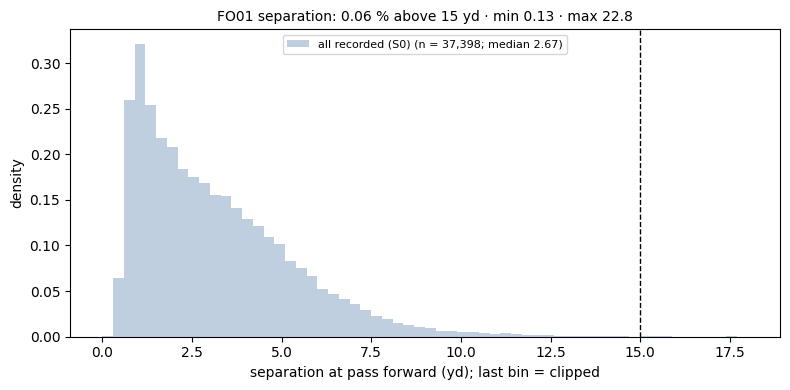

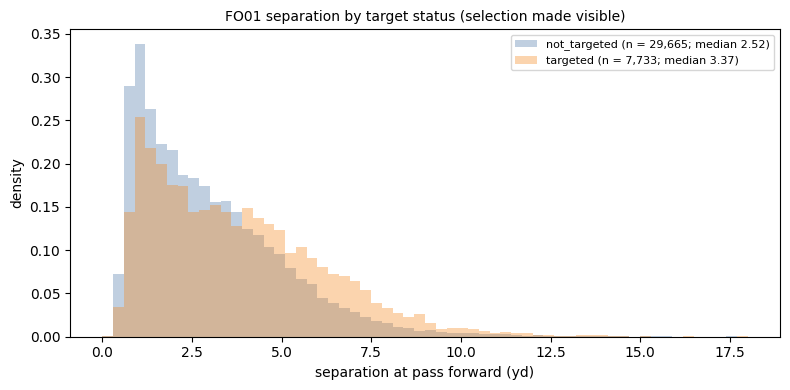

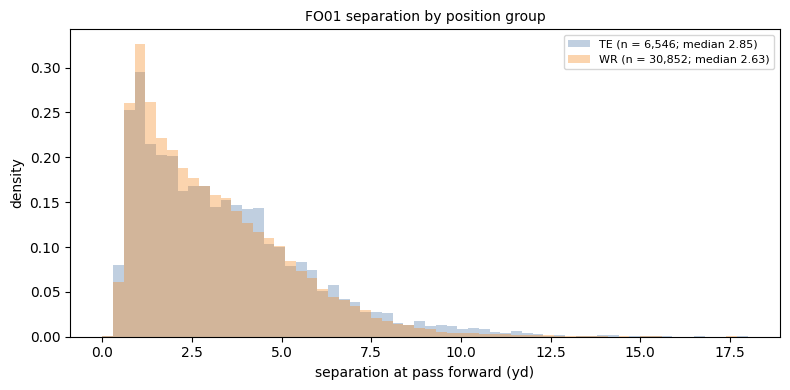

In [6]:
sep_rows = osm.fo01_rows(base)
sep_dist, structure = sem[osm.SEP_DIST.name], sem[osm.STRUCTURE.name]
with pl.Config(tbl_rows=-1, tbl_width_chars=260, float_precision=3):
    display(sep_dist)
    display(structure.filter((pl.col('outcome_id') == osm.FO01) & pl.col('group_field').is_in(['target', 'has:route_ran', 'play_class', 'season',
                                                                                                 'team_coverage_man_zone'])))
N_SEP = f'{sep_rows.height:,} recorded separations · {sep_rows["nfl_id"].n_unique()} athletes'
store.show(ovf.fig_separation(sep_rows, vc.extreme_yd), 'AM08A2_03_separation_distribution', {'distribution': sep_dist},
           source='silver.player_play.separation_at_pass_forward (eligible WR / TE player-plays)', n=N_SEP,
           note=f'values above {vc.extreme_yd} yd are clipped into the last bin for display only')
store.show(ovf.fig_separation_by(sep_rows, 'target', vc.extreme_yd, 'FO01 separation by target status (selection made visible)'),
           'AM08A2_04_separation_by_target', {'distribution': sep_dist}, source='football_separation_distribution', n=N_SEP)
store.show(ovf.fig_separation_by(sep_rows, 'position_group', vc.extreme_yd, 'FO01 separation by position group'),
           'AM08A2_05_separation_by_position', {'distribution': sep_dist}, source='football_separation_distribution', n=N_SEP)

## 4. Context relevance; route × alignment coverage

For each context field: is it recorded, what does it mean, is it known before the snap, is it observed after the outcome, and what would using it do?

**Boundary for every later notebook.** An NFL context field may *define or interpret* an NFL outcome (for example the route × alignment adjustment of S2). It may **not** be a predictor of a pre-draft model: none of them is available at the draft (`available_pre_draft = false`), and several are observed after the outcome. Adjusting for a context also **changes the estimand**: S2 compares athletes inside the routes and alignments their NFL team chose for them.

A route × alignment cell is *supported* by counts only (observations and athletes), never by its values.

field,source,present,observed_share,interpretation,known_pre_snap,observed_after_outcome,available_pre_draft,leakage_as_predictor,changes_estimand
str,str,bool,f64,str,str,bool,bool,str,str
"""position_group""","""gold.dim_athlete""",true,1.000,"""roster position group of the athlete""","""yes""",false,true,"""none (the Combine position is known at the draft)""","""no: defines the comparison population"""
"""lined_up_position""","""player_play""",true,0.991,"""alignment of the player on the play""","""yes""",false,false,"""future NFL role: forbidden in a pre-draft model""","""yes: an alignment-adjusted value compares players inside an NFL role the team chose"""
"""route_ran""","""player_play""",true,0.177,"""route label of the player (an assignment label)""","""partly (play design; labelled after the play)""",true,false,"""future NFL usage: forbidden in a pre-draft model""","""yes: a route-adjusted value removes route mix, which is partly a property of the player"""
"""target""","""player_play""",true,0.991,"""the pass was thrown to the player""","""no""",true,false,"""outcome-dependent (the quarterback chooses the open receiver): never a predictor, never a filter of the primary target""","""yes: conditioning on it selects plays on the outcome"""
"""cushion""","""player_play""",true,0.345,"""pre-snap distance to the defender across""","""yes""",false,false,"""future NFL context: forbidden in a pre-draft model""","""yes: adjusts for how the defence chose to play the receiver"""
"""play_class""","""nfl_play_movement (from pass_result)""",true,1.000,"""pass · sack_or_scramble · no_pass (empty code INFERRED)""","""no""",true,false,"""play result: forbidden""","""yes when used as a filter: selects plays by their result"""
"""team_coverage_man_zone""","""player_play""",false,null,"""coverage family of the defence""","""no (labelled after the play)""",true,false,"""future NFL context: forbidden""","""yes: separation against man and against zone are different quantities"""
"""coverage_assignment""","""player_play""",true,0.283,"""assignment label of a defender (NO_ASSIGNMENT is a vendor token)""","""partly""",true,false,"""future NFL role: forbidden""","""yes: reading NO_ASSIGNMENT as 'rushed the passer' is an inference"""
"""season""","""silver.games""",true,1.000,"""NFL season of the game""","""yes""",false,false,"""not a predictor; the draft cohort (known at the draft) is the allowed counterpart""","""no: used for coverage and stability reporting"""


route_ran,lined_up_position,n_obs,n_athletes,mean_value,supported
str,str,i64,i64,f64,bool
"""GO""","""WR""",4456,103,2.458,true
"""HITCH""","""WR""",3568,99,3.033,true
"""IN""","""WR""",2392,98,2.981,true
"""CROSS""","""WR""",2073,94,3.442,true
"""GO""","""SLOT_WR""",1983,104,2.937,true
"""HITCH""","""SLOT_WR""",1980,100,3.250,true
"""POST""","""WR""",1836,93,2.811,true
"""CROSS""","""SLOT_WR""",1803,97,3.035,true
"""OUT""","""WR""",1687,90,3.078,true


supported cells: 26 of 40 (rule: >= 200 observations and >= 15 athletes)


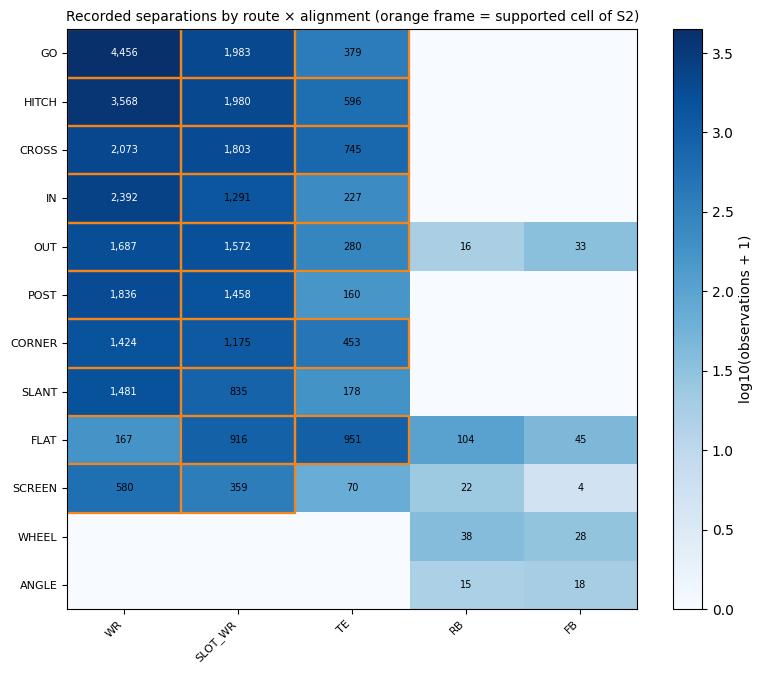

In [7]:
context, cells = sem[osm.CONTEXT_T.name], sem[osm.CELLS.name]
with pl.Config(fmt_str_lengths=200, tbl_rows=-1, tbl_width_chars=320, float_precision=3):
    display(context)
    display(cells.head(40))
print(f'supported cells: {int(cells["supported"].sum())} of {cells.height} '
      f'(rule: >= {vc.min_cell_obs} observations and >= {vc.min_cell_athletes} athletes)')
store.show(ovf.fig_context_cells(cells), 'AM08A2_06_route_alignment_coverage', {'cells': cells},
           source='football_separation_context_cells', n=f'{int(cells["n_obs"].sum()):,} recorded separations with a route label',
           note='orange frame = supported cell of denominator S2')

## 5. FO12 tackle and FO13 sack — opportunity structure

**Tackle.** Read three things: (i) on which share of defensive player-plays a tackle value is recorded at all; (ii) what a recorded 0 is (check `zero_explained_by_assist`); (iii) that no field records a tackle *opportunity*. If the recorded rows exist only when a statistic was credited, `mean(tackle | recorded)` is the solo share among credited plays — not a tackle rate — and non-successes are **not** manufactured.

**Sack.** Read on which plays an explicit 0 is recorded (`play_class`, coverage label): the recorded rows are the candidate denominator `K0`. Whether the player rushed the passer on them is not recorded; reading `NO_ASSIGNMENT` as “rushed” (`K1`) is an inference and stays a sensitivity analysis.

outcome_id,group_field,group_value,n_rows,n_obs,obs_share,n_zero,n_positive,mean_value
str,str,str,i64,i64,f64,i64,i64,f64
"""FO12.tackle""","""position_group""","""DB""",63914,5799,0.0907,1947,3852,0.6643
"""FO12.tackle""","""position_group""","""DL""",50363,3444,0.0684,1683,1761,0.5113
"""FO12.tackle""","""play_class""","""pass""",60758,3712,0.0611,919,2793,0.7524
"""FO12.tackle""","""play_class""","""no_pass""",45426,4822,0.1062,2561,2261,0.4689
"""FO12.tackle""","""play_class""","""sack_or_scramble""",8093,709,0.0876,150,559,0.7884
"""FO12.tackle""","""has:assist""","""‹null›""",105034,0,0.0000,0,0,null
"""FO12.tackle""","""has:assist""","""recorded""",9243,9243,1.0000,3630,5613,0.6073
"""FO12.tackle""","""assist""","""‹null›""",105034,0,0.0000,0,0,null
"""FO12.tackle""","""assist""","""0""",5616,5616,1.0000,3,5613,0.9995


outcome_id,group_field,group_value,n_rows,n_obs,obs_share,n_zero,n_positive,mean_value
str,str,str,i64,i64,f64,i64,i64,f64
"""FO13.sack""","""position_group""","""DL""",50363,28962,0.5751,28567,395,0.0121
"""FO13.sack""","""play_class""","""pass""",25788,25548,0.9907,25548,0,0.0000
"""FO13.sack""","""play_class""","""no_pass""",21211,103,0.0049,103,0,0.0000
"""FO13.sack""","""play_class""","""sack_or_scramble""",3364,3311,0.9842,2916,395,0.1054
"""FO13.sack""","""has:coverage_assignment""","""recorded""",29044,28952,0.9968,28557,395,0.0121
"""FO13.sack""","""has:coverage_assignment""","""‹null›""",21319,10,0.0005,10,0,0.0000
"""FO13.sack""","""coverage_assignment""","""NO_ASSIGNMENT""",27068,27058,0.9996,26667,391,0.0128
"""FO13.sack""","""coverage_assignment""","""‹null›""",21319,10,0.0005,10,0,0.0000
"""FO13.sack""","""coverage_assignment""","""HOLE""",461,384,0.8330,384,0,0.0000


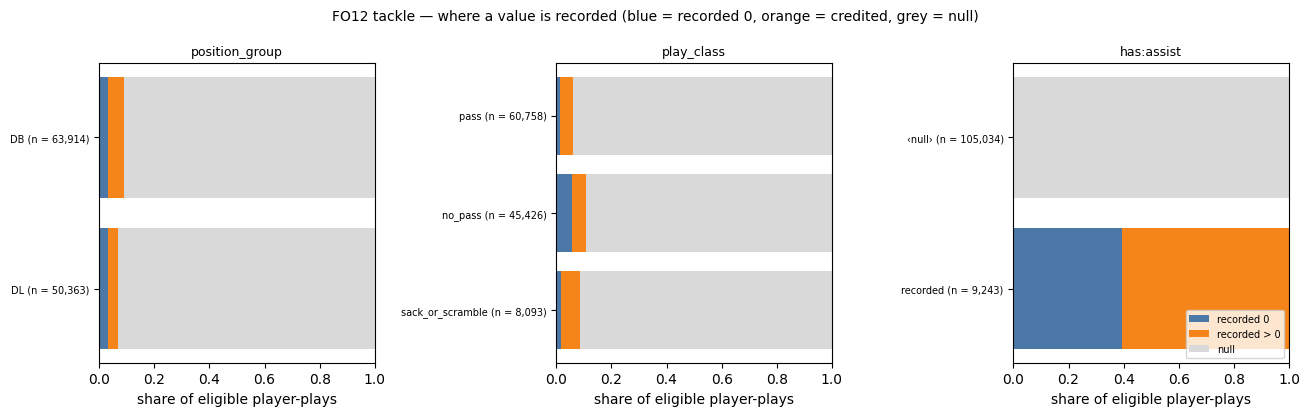

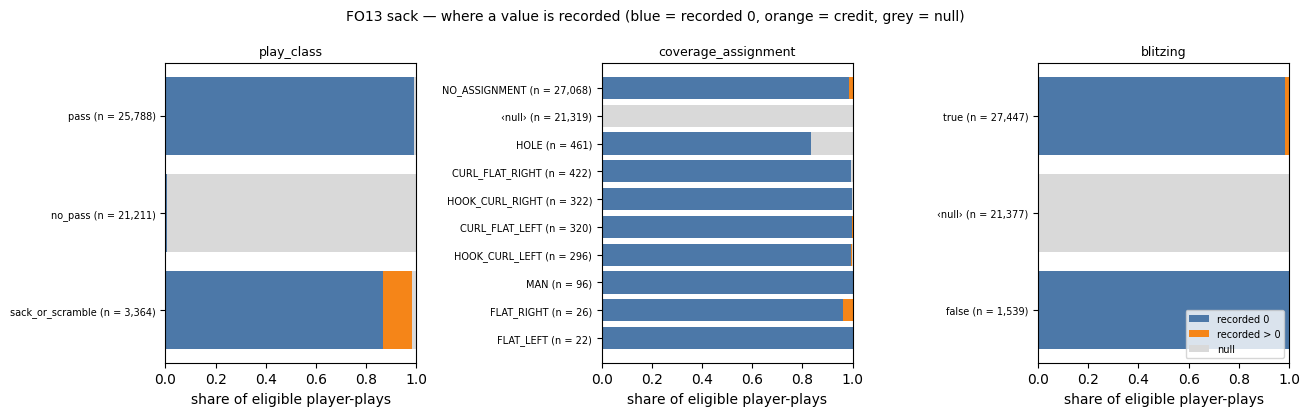

In [8]:
with pl.Config(tbl_rows=-1, tbl_width_chars=240, float_precision=4):
    display(structure.filter(pl.col('outcome_id') == osm.FO12))
    display(structure.filter(pl.col('outcome_id') == osm.FO13))
store.show(ovf.fig_structure(structure, osm.FO12, ('position_group', 'play_class', 'has:assist'),
                             'FO12 tackle — where a value is recorded (blue = recorded 0, orange = credited, grey = null)'),
           'AM08A2_07_tackle_opportunity_structure', {'structure': structure.filter(pl.col('outcome_id') == osm.FO12)},
           source='football_outcome_structure', n='eligible DB / DL player-plays')
store.show(ovf.fig_structure(structure, osm.FO13, ('play_class', 'coverage_assignment', 'blitzing'),
                             'FO13 sack — where a value is recorded (blue = recorded 0, orange = credit, grey = null)'),
           'AM08A2_08_sack_opportunity_structure', {'structure': structure.filter(pl.col('outcome_id') == osm.FO13)},
           source='football_outcome_structure', n='eligible DL player-plays')

## 6. Opportunity denominators

Declared in `opportunity_validation.DENOMINATORS` before reading a value. Only denominators whose fields exist are computed.

| ID | Population | Legitimacy |
|---|---|---|
| `FO01.S0` | every eligible player-play with a recorded separation | recorded |
| `FO01.S1` | S0 with a recorded `route_ran` | recorded |
| `FO01.S2` | S1 in supported route × alignment cells, value = separation − cell mean | recorded (context-adjusted estimand) |
| `FO01.S0T` / `S0N` | targeted / not targeted only | selected — sensitivity only |
| `FO12.T0` | rows with a recorded tackle statistic | credited only — sensitivity only |
| `FO12.T1` / `T2` | credited tackles (+ assists) per tracked snap | structural: null read as “no credit” |
| `FO13.K0` | sack credit per recorded row | recorded |
| `FO13.K1` | K0 rows with `NO_ASSIGNMENT` | inferred — sensitivity only |
| `FO13.K2` | sack credit per tracked snap | structural: null read as “no credit” |

Athlete support = at least `min_obs` rows in at least `min_games` games. Nothing here is a rate per *opportunity* unless the table says the opportunity is recorded.

In [9]:
def _opportunity():
    t0 = time.perf_counter()
    return ov.run_opportunity(base, vc, progress=lambda m: print(f'[{time.perf_counter() - t0:5.0f} s] {m}'))


opp = store.build('08a2_opportunity', ov.OPPORTUNITY_CONTRACTS, _opportunity, params=PARAMS, files=[PLAYS_FILE, *PP_FILES])
denoms, seasons, athletes = opp[ov.DENOMS.name], opp[ov.SEASONS.name], opp[ov.ATHLETES.name]
reliability, exposure, ranking, dependence = (opp[c.name] for c in (ov.RELIABILITY, ov.EXPOSURE, ov.RANKING, ov.DEPENDENCE))
with pl.Config(fmt_str_lengths=160, tbl_rows=-1, tbl_width_chars=300, float_precision=4):
    display(denoms.filter(pl.col('position_group') == ov.ALL).select('denominator_id', 'legitimacy', 'kind', 'unit', 'available', 'formula', 'assumption'))
    display(denoms.select('denominator_id', 'position_group', 'n_rows', 'n_athletes_any', 'n_athletes_supported', 'n_athlete_games',
                          'median_obs', 'median_games', 'mean_value', 'targeted_share'))
    display(seasons)

18:40:02 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:08a2_opportunity] computing (never run)


[    0 s] FO01.S0: 37,398 rows · 116 athletes · 102 supported
[    0 s] FO01.S1: 37,398 rows · 116 athletes · 102 supported
[    1 s] FO01.S2: 36,500 rows · 115 athletes · 101 supported
[    1 s] FO01.S0T: 7,733 rows · 107 athletes · 77 supported
[    1 s] FO01.S0N: 29,665 rows · 116 athletes · 101 supported
[    1 s] FO12.T0: 9,243 rows · 178 athletes · 114 supported
[    1 s] FO12.T1: 114,277 rows · 194 athletes · 171 supported
[    2 s] FO12.T2: 114,277 rows · 194 athletes · 171 supported
[    2 s] FO13.K0: 28,962 rows · 98 athletes · 87 supported
[    2 s] FO13.K1: 27,058 rows · 98 athletes · 87 supported
[    2 s] FO13.K2: 50,363 rows · 98 athletes · 91 supported


18:40:04 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08a2_opportunity] football_opportunity_denominators: 30 rows → warehouse/gold/advanced_movement/scouting_v1/football_opportunity_denominators.parquet
18:40:04 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08a2_opportunity] football_opportunity_seasons: 33 rows → warehouse/gold/advanced_movement/scouting_v1/football_opportunity_seasons.parquet
18:40:04 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08a2_opportunity] football_outcome_athlete_values: 1,430 rows → warehouse/gold/advanced_movement/scouting_v1/football_outcome_athlete_values.parquet
18:40:04 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08a2_opportunity] football_outcome_reliability: 54 rows → warehouse/gold/advanced_movement/scouting_v1/football_outcome_reliability.parquet
18:40:04 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08a2_opportunity] football_outc

denominator_id,legitimacy,kind,unit,available,formula,assumption
str,str,str,str,bool,str,str
"""FO01.S0""","""recorded""","""continuous""","""yd""",true,"""mean of separation_at_pass_forward over eligible player-plays with a recorded value""",""""""
"""FO01.S1""","""recorded""","""continuous""","""yd""",true,"""mean of separation_at_pass_forward over eligible player-plays with a recorded value AND a recorded route_ran""",""""""
"""FO01.S2""","""recorded""","""continuous""","""yd (residual)""",true,"""mean over S1 rows in supported route × alignment cells of (separation − cell mean)""","""cell means are estimated on all athletes here; a transfer model must refit them on training athletes"""
"""FO01.S0T""","""selected""","""continuous""","""yd""",true,"""mean of separation_at_pass_forward over S0 rows with target = true""","""the quarterback chooses the target: the plays are selected on the outcome"""
"""FO01.S0N""","""selected""","""continuous""","""yd""",true,"""mean of separation_at_pass_forward over S0 rows with target = false""","""complement of a selection on the outcome"""
"""FO12.T0""","""credited_only""","""rate""","""share of recorded rows""",true,"""mean of tackle over eligible player-plays with a recorded tackle value""","""the rows exist only when a tackle statistic was credited: non-successes are not observed"""
"""FO12.T1""","""structural""","""rate""","""tackles per eligible snap""",true,"""sum of (tackle > 0) over ALL eligible player-plays of the athlete / number of those player-plays""","""a null is read as 'no tackle credited'; snaps on the field are exposure, not tackle opportunities"""
"""FO12.T2""","""structural""","""rate""","""tackles or assists per eligible snap""",true,"""sum of (tackle > 0 or assist > 0) over ALL eligible player-plays of the athlete / number of those player-plays""","""a null is read as 'no credit'; snaps on the field are exposure, not tackle opportunities"""
"""FO13.K0""","""recorded""","""rate""","""sacks per recorded row""",true,"""mean of sack (0, 0.5, 1) over eligible player-plays with a recorded sack value""","""a recorded row is a defensive pass-play row; that the player rushed the passer on it is not recorded"""


denominator_id,position_group,n_rows,n_athletes_any,n_athletes_supported,n_athlete_games,median_obs,median_games,mean_value,targeted_share
str,str,i64,i64,i64,i64,f64,f64,f64,f64
"""FO01.S0""","""ALL""",37398,116,102,2528,193.5000,17.0000,3.1532,0.2068
"""FO01.S0""","""WR""",30852,83,75,1863,249.0000,17.0000,3.1100,0.2081
"""FO01.S0""","""TE""",6546,33,27,665,157.0000,17.0000,3.3569,0.2004
"""FO01.S1""","""ALL""",37398,116,102,2528,193.5000,17.0000,3.1532,0.2068
"""FO01.S1""","""WR""",30852,83,75,1863,249.0000,17.0000,3.1100,0.2081
"""FO01.S1""","""TE""",6546,33,27,665,157.0000,17.0000,3.3569,0.2004
"""FO01.S2""","""ALL""",36500,115,101,2517,192.0000,17.0000,0.0000,0.2049
"""FO01.S2""","""WR""",30425,83,75,1861,245.0000,17.0000,0.0062,0.2065
"""FO01.S2""","""TE""",6075,32,26,656,147.0000,17.0000,-0.0310,0.1965


denominator_id,season,n_rows,n_athletes,n_games,mean_value
str,i64,i64,i64,i64,f64
"""FO01.S0""",2023,7389,40,243,3.1850
"""FO01.S0""",2024,13142,76,270,3.1646
"""FO01.S0""",2025,16867,97,269,3.1303
"""FO01.S0N""",2023,5898,40,242,3.0259
"""FO01.S0N""",2024,10483,76,270,2.9959
"""FO01.S0N""",2025,13284,97,269,2.9754
"""FO01.S0T""",2023,1491,36,223,3.8143
"""FO01.S0T""",2024,2659,72,260,3.8296
"""FO01.S0T""",2025,3583,91,263,3.7047


## 7. Reliability across independent games

- **odd / even games** — chronological parity of the athlete's own games; athlete value centred within position; Spearman–Brown; 95 % interval from an athlete bootstrap.
- **random game halves** — the same statistic over random splits of each athlete's games (mean and spread over the splits).
- **first N games versus later games** — plain correlation (no step-up): does an early sample describe the later player?
- **at least G games** — odd / even reliability among better-exposed athletes.
- **exposure dependence** — Spearman of the athlete value with the log of its own number of rows (within position).

Halves are whole games, so a game-level effect (opponent, script) cannot pass for an athlete effect. Reliability says the value is *reproducible*, not that it is skill: a stable role or scheme is reproducible too.

Reference lines (heuristics, declared before running): reliability ≥ 0.70 with lower bound ≥ 0.50; |ρ exposure| ≤ 0.30.

denominator_id,outcome_id,split,position_group,n_athletes,r_half,rel_sb,rel_lo,rel_hi,interval_kind,note
str,str,str,str,i64,f64,f64,f64,f64,str,str
"""FO01.S0""","""FO01.separation_at_pass_forward""","""odd_even""","""ALL""",100,0.590,0.742,0.516,0.870,"""athlete_bootstrap""",""""""
"""FO01.S0""","""FO01.separation_at_pass_forward""","""random""","""ALL""",100,0.490,0.654,0.507,0.772,"""split_distribution""",""""""
"""FO01.S0""","""FO01.separation_at_pass_forward""","""odd_even""","""WR""",74,0.635,0.777,0.446,0.905,"""athlete_bootstrap""",""""""
"""FO01.S0""","""FO01.separation_at_pass_forward""","""random""","""WR""",74,0.545,0.702,0.547,0.840,"""split_distribution""",""""""
"""FO01.S0""","""FO01.separation_at_pass_forward""","""odd_even""","""TE""",26,0.453,0.624,0.376,0.853,"""athlete_bootstrap""",""""""
"""FO01.S0""","""FO01.separation_at_pass_forward""","""random""","""TE""",27,0.363,0.513,0.155,0.800,"""split_distribution""",""""""
"""FO01.S1""","""FO01.separation_at_pass_forward""","""odd_even""","""ALL""",100,0.590,0.742,0.504,0.871,"""athlete_bootstrap""",""""""
"""FO01.S1""","""FO01.separation_at_pass_forward""","""random""","""ALL""",100,0.480,0.645,0.504,0.760,"""split_distribution""",""""""
"""FO01.S1""","""FO01.separation_at_pass_forward""","""odd_even""","""WR""",74,0.635,0.777,0.510,0.906,"""athlete_bootstrap""",""""""


denominator_id,mode,level,n_athletes,r,rel_sb
str,str,i64,i64,f64,f64
"""FO01.S0""","""first_n_vs_later""",2,105,0.219,null
"""FO01.S0""","""first_n_vs_later""",4,102,0.384,null
"""FO01.S0""","""first_n_vs_later""",6,97,0.512,null
"""FO01.S0""","""first_n_vs_later""",8,91,0.548,null
"""FO01.S0""","""min_games""",4,99,0.589,0.742
"""FO01.S0""","""min_games""",8,95,0.595,0.746
"""FO01.S0""","""min_games""",12,86,0.762,0.865
"""FO01.S0""","""min_games""",16,71,0.755,0.860
"""FO01.S1""","""first_n_vs_later""",2,105,0.219,null


denominator_id,n_athletes,rho_value_log_obs,rho_value_games
str,i64,f64,f64
"""FO01.S0""",102,0.089,0.208
"""FO01.S1""",102,0.089,0.208
"""FO01.S2""",101,0.052,0.163
"""FO01.S0T""",77,0.104,0.201
"""FO01.S0N""",101,-0.001,0.142
"""FO12.T0""",114,0.185,0.318
"""FO12.T1""",171,0.136,0.192
"""FO12.T2""",171,0.032,0.088
"""FO13.K0""",87,0.601,0.521


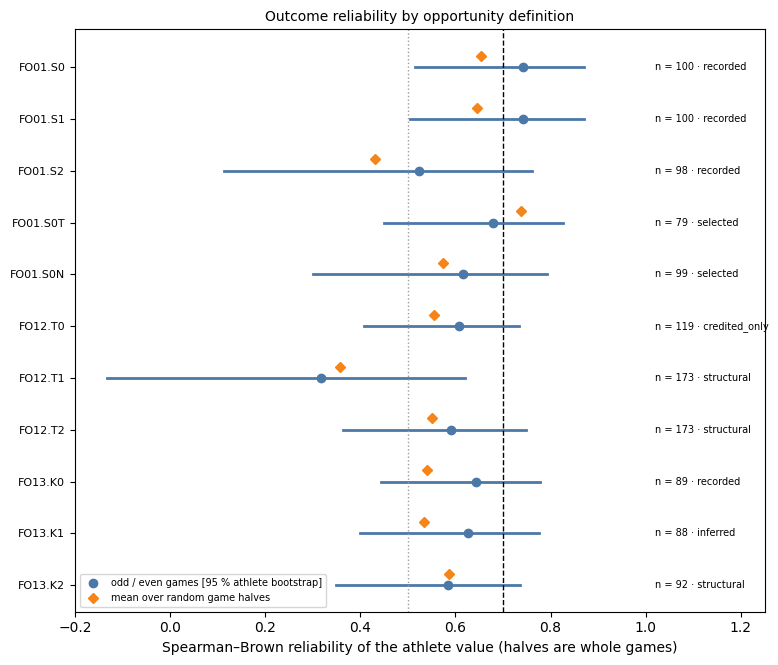

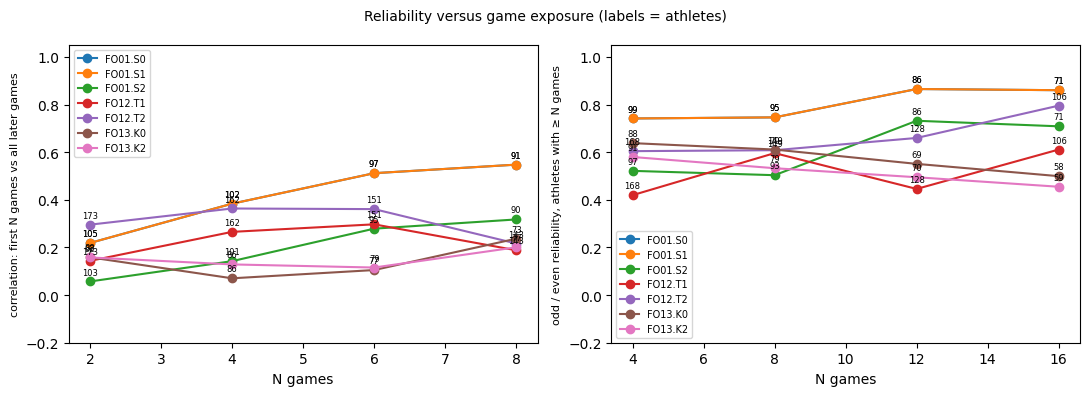

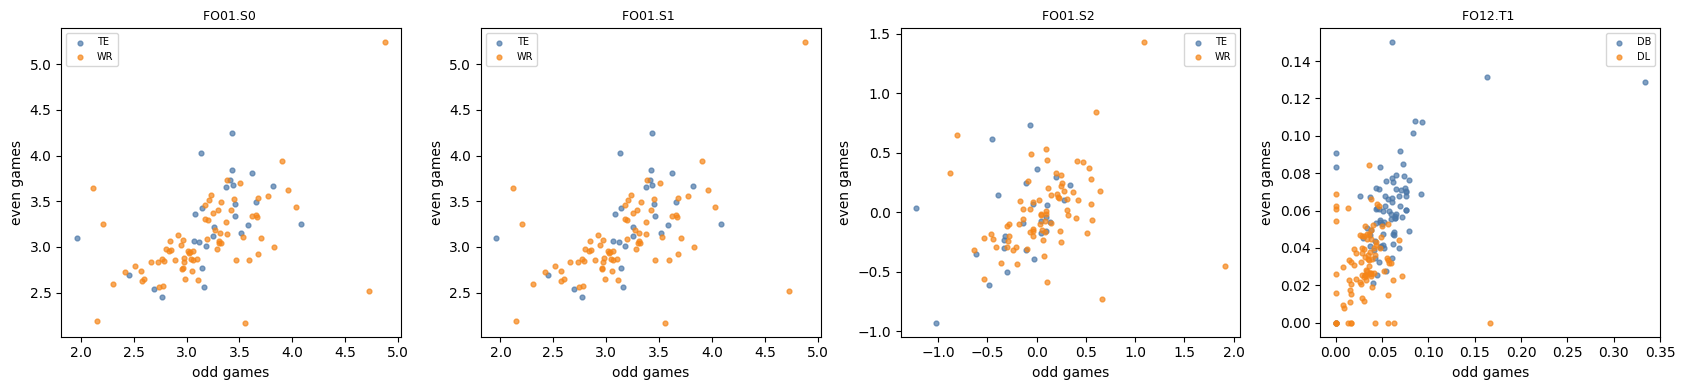

In [10]:
SHOW = [d.denominator_id for d in ov.DENOMINATORS if d.legitimacy in ov.FREEZABLE and d.denominator_id in athletes['denominator_id'].unique().to_list()]
with pl.Config(fmt_str_lengths=120, tbl_rows=-1, tbl_width_chars=260, float_precision=3):
    display(reliability)
    display(exposure)
    display(dependence)
N_ATH = f'{athletes.filter(pl.col("supported"))["nfl_id"].n_unique()} supported athletes over all denominators'
store.show(ovf.fig_reliability(reliability, vc), 'AM08A2_09_outcome_reliability', {'reliability': reliability},
           source='football_outcome_reliability', n=N_ATH,
           note=f'dashed = {vc.reliability_ref}, dotted = {vc.reliability_floor}; halves are whole games')
store.show(ovf.fig_reliability_exposure(exposure, SHOW), 'AM08A2_10_reliability_versus_exposure', {'exposure': exposure},
           source='football_outcome_reliability_exposure', n=N_ATH)
store.show(ovf.fig_halves(athletes, SHOW[:4]), 'AM08A2_09b_odd_even_game_values', {},
           source='football_outcome_athlete_values', n=N_ATH, note='supplement: athlete value in odd versus even games')

## 8. Does the opportunity rule change the ranking?

Within-position percentiles of the athletes supported by both definitions of one outcome: Spearman agreement and mean absolute percentile shift. `…|median` replaces the athlete mean by the median (sensitivity to extreme separations). A low agreement between S0 and S2 is not an error: S2 answers a different question (section 4).

outcome_id,definition_a,definition_b,position_group,n_common,spearman,mean_abs_pct_shift,max_abs_pct_shift
str,str,str,str,i64,f64,f64,f64
"""FO01.separation_at_pass_forwar…","""FO01.S0""","""FO01.S0|median""","""ALL""",102,0.915,8.819,40.741
"""FO01.separation_at_pass_forwar…","""FO01.S0""","""FO01.S0|median""","""TE""",27,0.877,10.700,40.741
"""FO01.separation_at_pass_forwar…","""FO01.S0""","""FO01.S0|median""","""WR""",75,0.930,8.142,25.333
"""FO01.separation_at_pass_forwar…","""FO01.S0""","""FO01.S1""","""ALL""",102,1.000,0.000,0.000
"""FO01.separation_at_pass_forwar…","""FO01.S0""","""FO01.S1""","""TE""",27,1.000,0.000,0.000
"""FO01.separation_at_pass_forwar…","""FO01.S0""","""FO01.S1""","""WR""",75,1.000,0.000,0.000
"""FO01.separation_at_pass_forwar…","""FO01.S0""","""FO01.S1|median""","""ALL""",102,0.915,8.819,40.741
"""FO01.separation_at_pass_forwar…","""FO01.S0""","""FO01.S1|median""","""TE""",27,0.877,10.700,40.741
"""FO01.separation_at_pass_forwar…","""FO01.S0""","""FO01.S1|median""","""WR""",75,0.930,8.142,25.333


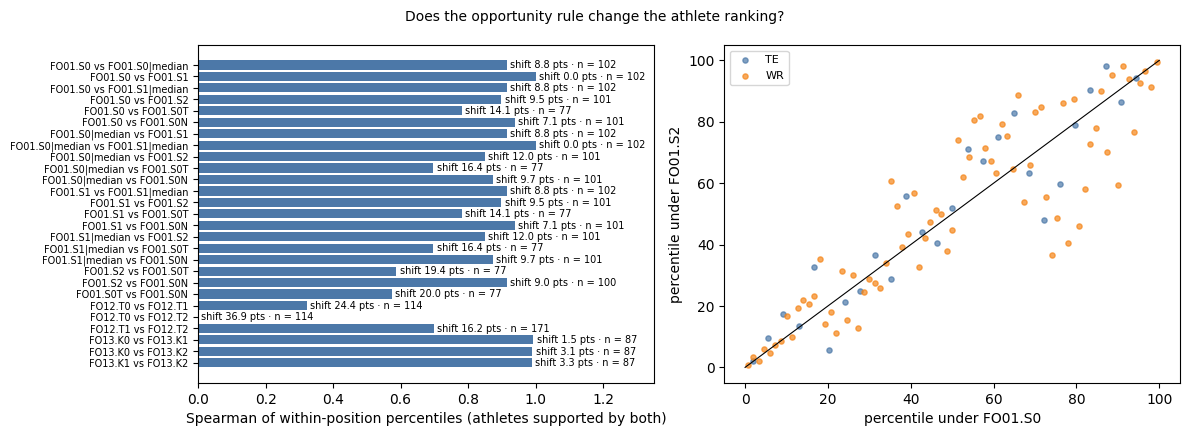

In [11]:
with pl.Config(tbl_rows=-1, tbl_width_chars=220, float_precision=3):
    display(ranking)
store.show(ovf.fig_ranking(ranking, athletes, ('FO01.S0', 'FO01.S2')), 'AM08A2_13_definition_ranking_sensitivity', {'ranking': ranking},
           source='football_outcome_ranking_sensitivity', n=N_ATH, note='right panel: FO01.S0 against FO01.S2 (context-adjusted)')

## 9. Linked Combine cohort

Each denominator has **its own** linked population — the 284 athletes of Milestone 06 are not reused. Funnel: NFL rows → NFL support → Combine-linked → official tests → valid tracking → every model family (M0–M6 of 08B). Side counts: repeat attempts, and eligibility per model family.

Only linkage flags and counts are read. No Combine measurement enters this notebook, so no definition can have been tuned on a Combine association.

18:40:09 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:08a2_linked_cohort] computing (never run)
18:40:09 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08a2_linked_cohort] football_outcome_athlete_links: 1,430 rows → warehouse/gold/advanced_movement/scouting_v1/football_outcome_athlete_links.parquet
18:40:09 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08a2_linked_cohort] football_outcome_linked_cohort: 330 rows → warehouse/gold/advanced_movement/scouting_v1/football_outcome_linked_cohort.parquet
18:40:09 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08a2_linked_cohort] football_outcome_cohort_support: 57 rows → warehouse/gold/advanced_movement/scouting_v1/football_outcome_cohort_support.parquet


denominator_id,position_group,nfl_observed,nfl_supported,combine_linked,official_tests,valid_tracking,all_model_families,repeat_attempts,eligible_M2_engineered,eligible_M3_speed,eligible_M4_fpca,eligible_M5_tcn
str,str,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64
"""FO01.S0""","""ALL""",116,102,102,93,91,91,79,91,91,91,91
"""FO01.S0""","""TE""",33,27,27,24,24,24,22,24,24,24,24
"""FO01.S0""","""WR""",83,75,75,69,67,67,57,67,67,67,67
"""FO01.S1""","""ALL""",116,102,102,93,91,91,79,91,91,91,91
"""FO01.S1""","""TE""",33,27,27,24,24,24,22,24,24,24,24
"""FO01.S1""","""WR""",83,75,75,69,67,67,57,67,67,67,67
"""FO01.S2""","""ALL""",115,101,101,92,90,90,78,90,90,90,90
"""FO01.S2""","""TE""",32,26,26,23,23,23,21,23,23,23,23
"""FO01.S2""","""WR""",83,75,75,69,67,67,57,67,67,67,67


denominator_id,position_group,draft_year,n_supported_linked,n_all_models
str,str,i64,i64,i64
"""FO01.S0""","""TE""",2023,8,8
"""FO01.S0""","""TE""",2024,11,10
"""FO01.S0""","""TE""",2025,8,6
"""FO01.S0""","""WR""",2023,30,25
"""FO01.S0""","""WR""",2024,26,24
"""FO01.S0""","""WR""",2025,19,18
"""FO01.S1""","""TE""",2023,8,8
"""FO01.S1""","""TE""",2024,11,10
"""FO01.S1""","""TE""",2025,8,6


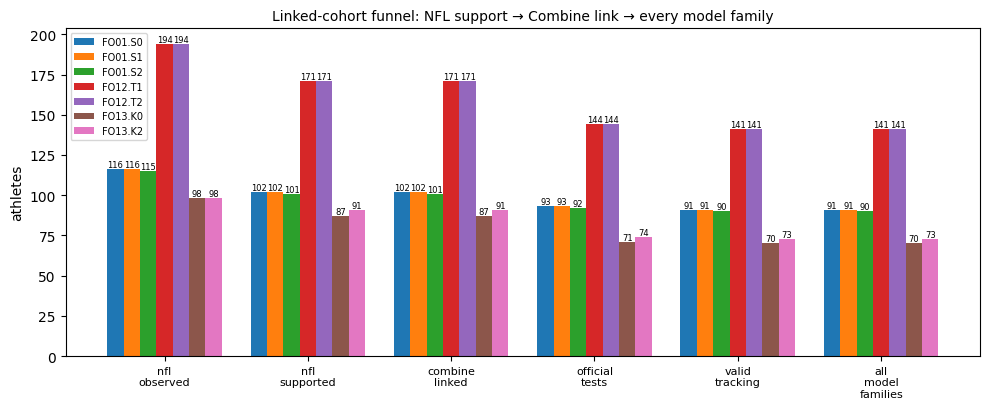

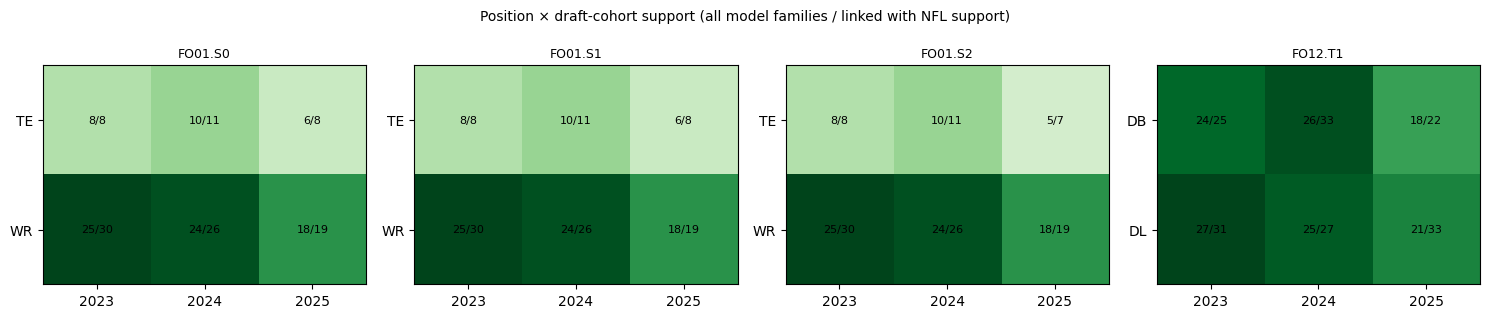

In [12]:
lk = store.build('08a2_linked_cohort', ov.LINK_CONTRACTS, lambda: ov.run_links(athletes, manifest), params=PARAMS,
                 files=[PLAYS_FILE, MANIFEST_FILE, *PP_FILES])
links, funnel, support = lk[ov.LINKS.name], lk[ov.FUNNEL.name], lk[ov.SUPPORT.name]
wide = (funnel.filter(pl.col('denominator_id').is_in(SHOW)).sort('stage_order')
        .pivot(on='stage', index=['denominator_id', 'position_group'], values='n_athletes').sort('denominator_id', 'position_group'))
with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=320):
    display(wide)
    display(support.filter(pl.col('denominator_id').is_in(SHOW)))
store.show(ovf.fig_funnel(funnel, SHOW), 'AM08A2_11_linked_cohort_funnel', {'funnel': funnel}, source='football_outcome_linked_cohort',
           n=f'{manifest.height} Combine athletes in the Milestone 06 manifest')
store.show(ovf.fig_support_heatmap(support, SHOW[:4]), 'AM08A2_12_position_cohort_support', {'support': support},
           source='football_outcome_cohort_support', n='linked athletes with NFL support', note='cell = all model families / linked with support')

## 10. Readiness screen and rule-based proposal

Ordered rule on declarations, counts and NFL-side reliability:

`unavailable` (field absent) → `sensitivity_only` (selected / credited-only / inferred denominator) → `rejected` (unresolved definition · too few linked athletes · reliability not assessable, below the floor, or lower bound not positive) → `eligible` (confirmed definition **and** recorded denominator **and** reliability at the reference line **and** low exposure dependence) → otherwise `provisional`, with the unmet criteria written out.

The proposal takes the first eligible (else provisional) denominator in the pre-declared order `FO01.S0 → S1 → S2 → FO13.K0 → FO12.T1 → T2 → FO13.K2`, then one denominator per other outcome. **It is a recommendation. It freezes nothing.**

In [13]:
sc = store.build('08a2_screen', [ov.SCREEN],
                 lambda: {ov.SCREEN.name: ov.screen_table(denoms, SEMANTIC, reliability, dependence, funnel, vc)},
                 params=PARAMS, files=[PLAYS_FILE, MANIFEST_FILE, *PP_FILES])
screen = sc[ov.SCREEN.name]
PROPOSAL = ov.propose(screen)
with pl.Config(fmt_str_lengths=260, tbl_rows=-1, tbl_cols=-1, tbl_width_chars=340, float_precision=3):
    display(screen)
print('rule-based proposal (NOT a freeze):', {k: PROPOSAL[k] for k in ('decision', 'primary', 'secondary', 'basis')})

18:40:11 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:08a2_screen] computing (never run)
18:40:11 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08a2_screen] football_outcome_screen: 11 rows → warehouse/gold/advanced_movement/scouting_v1/football_outcome_screen.parquet


denominator_id,outcome_id,legitimacy,semantic_status,unit,available,n_supported,n_linked_all_models,n_positions_linked,rel_sb,rel_lo,rel_hi,rel_random,exposure_rho,c_semantics,c_denominator,c_support,c_reliability,c_exposure,status,reason
str,str,str,str,str,bool,i64,i64,i64,f64,f64,f64,f64,f64,bool,bool,bool,bool,bool,str,str
"""FO01.S0""","""FO01.separation_at_pass_forward""","""recorded""","""plausible_inferred""","""yd""",true,102,91,2,0.742,0.516,0.870,0.654,0.089,false,true,true,true,true,"""provisional""","""unmet: vendor definition not confirmed"""
"""FO01.S1""","""FO01.separation_at_pass_forward""","""recorded""","""plausible_inferred""","""yd""",true,102,91,2,0.742,0.504,0.871,0.645,0.089,false,true,true,true,true,"""provisional""","""unmet: vendor definition not confirmed"""
"""FO01.S2""","""FO01.separation_at_pass_forward""","""recorded""","""plausible_inferred""","""yd (residual)""",true,101,90,2,0.523,0.113,0.760,0.431,0.052,false,true,true,false,true,"""provisional""","""unmet: vendor definition not confirmed; reliability below 0.70 / lower bound below 0.50"""
"""FO01.S0T""","""FO01.separation_at_pass_forward""","""selected""","""plausible_inferred""","""yd""",true,77,68,2,0.678,0.449,0.826,0.738,0.104,false,false,true,false,true,"""sensitivity_only""","""selected denominator: the quarterback chooses the target: the plays are selected on the outcome"""
"""FO01.S0N""","""FO01.separation_at_pass_forward""","""selected""","""plausible_inferred""","""yd""",true,101,90,2,0.616,0.300,0.792,0.574,-0.001,false,false,true,false,true,"""sensitivity_only""","""selected denominator: complement of a selection on the outcome"""
"""FO12.T0""","""FO12.tackle""","""credited_only""","""plausible_inferred""","""share of recorded rows""",true,114,93,2,0.608,0.408,0.734,0.554,0.185,false,false,true,false,true,"""sensitivity_only""","""credited_only denominator: the rows exist only when a tackle statistic was credited: non-successes are not observed"""
"""FO12.T1""","""FO12.tackle""","""structural""","""plausible_inferred""","""tackles per eligible snap""",true,171,141,2,0.317,-0.133,0.619,0.358,0.136,false,false,true,false,true,"""rejected""","""game-split reliability is not assessable, below the floor, or its lower bound is not positive"""
"""FO12.T2""","""FO12.tackle""","""structural""","""plausible_inferred""","""tackles or assists per eligible snap""",true,171,141,2,0.590,0.364,0.748,0.550,0.032,false,false,true,false,true,"""provisional""","""unmet: vendor definition not confirmed; denominator is structural; reliability below 0.70 / lower bound below 0.50"""
"""FO13.K0""","""FO13.sack""","""recorded""","""plausible_inferred""","""sacks per recorded row""",true,87,70,1,0.642,0.444,0.778,0.540,0.601,false,true,true,false,false,"""provisional""","""unmet: vendor definition not confirmed; reliability below 0.70 / lower bound below 0.50; |ρ(value, log exposure)| above 0.30"""


rule-based proposal (NOT a freeze): {'decision': 'PROVISIONAL', 'primary': 'FO01.S0', 'secondary': ['FO13.K0', 'FO12.T2'], 'basis': "first provisional denominator in the pre-declared order ['FO01.S0', 'FO01.S1', 'FO01.S2', 'FO13.K0', 'FO12.T1', 'FO12.T2', 'FO13.K2']; one denominator per other outcome"}


## 11. Explicit manual freeze — gate 08A.2

Set the decision yourself after reading sections 1–10, then run the two cells below.

- `DECISION = 'FREEZE'` — writes `football_outcome_targets_<REGISTRY_VERSION>.json` (immutable). Each target needs screen status `eligible`, **or** `provisional` together with `ACKNOWLEDGE_PROVISIONAL = True` and a `RATIONALE` that addresses every unmet criterion (for example: “vendor definition not in the repository; accepted as inferred, results labelled exploratory”).
- `DECISION = 'PROVISIONAL'` — definitions recorded for review; **no registry is written; 08B stays blocked**.
- `DECISION = 'STOP'` — no football outcome accepted; 08B does not run; Milestone 08 continues with 08C / 08D.
- `DECISION = None` — pending.

`PRIMARY` / `SECONDARY` are **denominator IDs** (for example `'FO01.S0'`), one per outcome, at most two secondaries. `rejected`, `sensitivity_only` and `unavailable` denominators are refused. A frozen registry is never overwritten: a changed definition needs a new `REGISTRY_VERSION` (`'v2'`), and the old file stays.

The registry also freezes the **primary metric** of 08B for each target, before any prediction exists. `nfl_movement_targets_v1` (Milestone 05) is not touched.

In [14]:
DECISION = None                 # None | 'FREEZE' | 'PROVISIONAL' | 'STOP'
PRIMARY = None                  # a denominator ID, e.g. 'FO01.S0'
SECONDARY = []                  # at most two denominator IDs of OTHER outcomes
RATIONALE = ""                  # required for every decision
ACKNOWLEDGE_PROVISIONAL = False  # True = you accept the unmet criteria listed in the screen for a provisional target
REGISTRY_VERSION = 'v1'         # a changed definition needs a new version; an existing registry is never overwritten

freeze: PENDING REVIEW — set DECISION to 'FREEZE', 'PROVISIONAL' or 'STOP' and rerun this cell


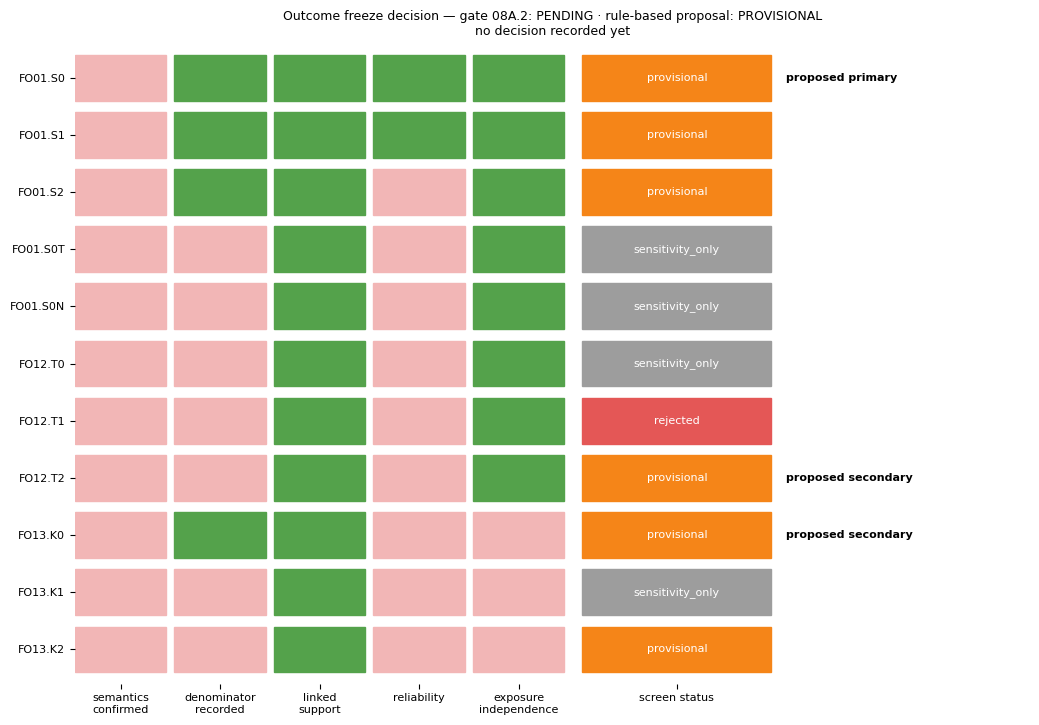

### 08A.2 — outcome semantics and opportunity validation

Gate 08A.2: **PENDING** — no decision recorded yet

| Outcome | Definition status | Basis |
|---|---|---|
| `FO01.separation_at_pass_forward` | plausible_inferred | inferred from the column name and internal consistency; no vendor definition recorded |
| `FO12.tackle` | plausible_inferred | inferred from the column name and internal consistency; no vendor definition recorded |
| `FO13.sack` | plausible_inferred | inferred from the column name and internal consistency; no vendor definition recorded |

| Denominator | Legitimacy | Linked (all models) | Odd / even reliability [95 %] | Random halves | ρ exposure | Status | Reason |
|---|---|---|---|---|---|---|---|
| `FO01.S0` | recorded | 91 | 0.74 [0.52, 0.87] | 0.65 | 0.09 | provisional | unmet: vendor definition not confirmed |
| `FO01.S1` | recorded | 91 | 0.74 [0.50, 0.87] | 0.65 | 0.09 | provisional | unmet: vendor definition not confirmed |
| `FO01.S2` | recorded | 90 | 0.52 [0.11, 0.76] | 0.43 | 0.05 | provisional | unmet: vendor definition not confirmed; reliability below 0.70 / lower bound below 0.50 |
| `FO01.S0T` | selected | 68 | 0.68 [0.45, 0.83] | 0.74 | 0.10 | sensitivity_only | selected denominator: the quarterback chooses the target: the plays are selected on the outcome |
| `FO01.S0N` | selected | 90 | 0.62 [0.30, 0.79] | 0.57 | -0.00 | sensitivity_only | selected denominator: complement of a selection on the outcome |
| `FO12.T0` | credited_only | 93 | 0.61 [0.41, 0.73] | 0.55 | 0.18 | sensitivity_only | credited_only denominator: the rows exist only when a tackle statistic was credited: non-successes are not observed |
| `FO12.T1` | structural | 141 | 0.32 [-0.13, 0.62] | 0.36 | 0.14 | rejected | game-split reliability is not assessable, below the floor, or its lower bound is not positive |
| `FO12.T2` | structural | 141 | 0.59 [0.36, 0.75] | 0.55 | 0.03 | provisional | unmet: vendor definition not confirmed; denominator is structural; reliability below 0.70 / lower bound below 0.50 |
| `FO13.K0` | recorded | 70 | 0.64 [0.44, 0.78] | 0.54 | 0.60 | provisional | unmet: vendor definition not confirmed; reliability below 0.70 / lower bound below 0.50; |ρ(value, log exposure)| above 0.30 |
| `FO13.K1` | inferred | 70 | 0.63 [0.40, 0.78] | 0.53 | 0.61 | sensitivity_only | inferred denominator: NO_ASSIGNMENT is read as 'rushed the passer': an inference about the assignment |
| `FO13.K2` | structural | 73 | 0.58 [0.35, 0.74] | 0.59 | 0.61 | provisional | unmet: vendor definition not confirmed; denominator is structural; reliability below 0.70 / lower bound below 0.50; |ρ(value, log exposure)| above 0.30 |

Rule-based proposal (a recommendation, not a freeze): **PROVISIONAL** · primary `FO01.S0` · secondary ['FO13.K0', 'FO12.T2'] — first provisional denominator in the pre-declared order ['FO01.S0', 'FO01.S1', 'FO01.S2', 'FO13.K0', 'FO12.T1', 'FO12.T2', 'FO13.K2']; one denominator per other outcome.

Reference lines (heuristics declared before running): ≥ 20 rows in ≥ 4 games per athlete; ≥ 60 linked athletes supporting every model family; odd / even Spearman–Brown ≥ 0.70 with a lower bound ≥ 0.50; |ρ(value, log exposure)| ≤ 0.30.

Limits: no vendor data dictionary in the repository (a definition is confirmed only by evidence the analyst records); the delivered tracking holds the project athletes only, so nearest-defender distance cannot be recomputed; assignment, opponent and scheme are unobserved; no Combine measurement was read and no outcome was related to one.

gate 08A.2: PENDING — no decision recorded yet


In [15]:
PROVENANCE = {'notebook': NB['08A2'], 'experiment_version': EXPERIMENT_VERSION, 'params': PARAMS, 'seed': controls.seed,
              'run_mode': controls.run_mode,
              'source_paths': {'player_play': SOURCE_FILES, 'nfl_play_movement': cfg.paths.rel(PLAYS_FILE),
                               'combine_cohort_manifest': cfg.paths.rel(MANIFEST_FILE)},
              'vendor_rows': DUP, 'absent_fields': ABSENT_FIELDS, 'feasibility_08a_status': status_08a,
              'nfl_movement_registry_read_only': registry_doc.get('version_hash')}

FROZEN, freeze_message = ov.freeze_football_targets(store, DECISION, PRIMARY, SECONDARY, RATIONALE, ACKNOWLEDGE_PROVISIONAL, screen=screen,
                                                    proposal=PROPOSAL, athletes=athletes, semantic=SEMANTIC, cfg=vc,
                                                    provenance=PROVENANCE, version=REGISTRY_VERSION)
GATE_08A2 = ov.gate_08a2(FROZEN, DECISION)
print(f'freeze: {freeze_message}')

store.show(ovf.fig_freeze_summary(screen, GATE_08A2, PROPOSAL, FROZEN), 'AM08A2_14_outcome_freeze_decision', {'screen': screen},
           source='football_outcome_screen', n=f'{screen.height} denominators', note=f'gate 08A.2: {GATE_08A2[0]}')

text = ov.conclusions_markdown(candidates, screen, PROPOSAL, GATE_08A2, vc)
display(Markdown(text))
if controls.save_tables:
    (store.tables_dir / 'football_outcome_validation_conclusions.md').write_text(text, encoding='utf-8')
    store.write_json(ov.PROPOSAL_FILE, {
        'rule_based_proposal': PROPOSAL, 'screen': screen.to_dicts(), 'semantic_status': SEMANTIC,
        'analyst': {'decision': DECISION, 'primary': PRIMARY, 'secondary': SECONDARY, 'rationale': RATIONALE,
                    'acknowledge_provisional': ACKNOWLEDGE_PROVISIONAL, 'registry_version': REGISTRY_VERSION},
        'gate_08a2': {'status': GATE_08A2[0], 'reading': GATE_08A2[1]}, 'freeze_message': freeze_message,
        'frozen_version_hash': (FROZEN or {}).get('version_hash'), 'provenance': PROVENANCE, 'finished_at': utc_now()})
print(f'gate 08A.2: {GATE_08A2[0]} — {GATE_08A2[1]}')

## Interpretation (to be written from the executed outputs — nothing is pre-filled)

- **FO01 semantics:** ‹status; is the value recorded for non-targeted receivers; unit check; what remains inferred›
- **FO01 opportunity rule:** ‹S0 vs S1 vs S2: support, reliability, ranking agreement; which question each answers›
- **FO12 tackle:** ‹what a recorded row is; whether any defensible exposure exists›
- **FO13 sack:** ‹where zeros are recorded; K0 as sacks per pass-defence row, not per rush›
- **Linked cohort:** ‹athletes per target supporting every model family; positions; draft cohorts›
- **Decision and reason:** ‹FREEZE / PROVISIONAL / STOP›

### Decision gate 08A.2

PASS only when at least one outcome has verified (or explicitly acknowledged) semantics, a correct unit, a legitimate opportunity denominator, sufficient linked support, adequate game-split reliability **and** an approved, written freeze. `PROVISIONAL`, `STOP` and `PENDING` all stop notebook 08B (`opportunity_validation.require_frozen`). A `STOP` is an accepted scientific result.

### What to send back

The validation table; the candidates and semantics-audit tables; `football_outcome_zero_missing` (rows shown) and `football_outcome_play_credit`; the separation distribution and the FO01 / FO12 / FO13 structure tables; the denominators table; reliability, exposure and dependence tables; the ranking table; the funnel (wide) table; the screen; the proposal line; the freeze and gate lines; figures 01, 04, 06, 07, 08, 09, 11, 13, 14; any traceback.

**Next.** Gate PASS → Phase B (notebook 08B) is authored on your instruction, on the frozen registry only. Otherwise 08B is not authored against a proposal; Phases C / D (08C, 08D) do not depend on this gate.